# Descriptives

## TOC 

- [Setup & Git](#setup)
- [Load and Preprocess Kern et al. & GPT Tweets](#load_preprocess_tweets)
- [Compare Prevalences](#compare_prevalences)
- [Check for Order Effects](#order_effects)

# Stuff to Check For / Analysis Ideas
- compare prevalences with those from Kern et al Paper 
- calculate agreement per tweets across the different conditions
- order effects (compare batch prompted with single-tweet prompted tweets)
- compare uncertainty measures per conditions (empirical entropy, confidence scores, etc.)

<a id="setup"></a>
## Setup & Git

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import os 
import pandas as pd
import re

<a id="load_preprocess_tweets"></a>
## Load and Preprocess the GPT Labelled Tweets

### Load the AS Paper tweets from Kern et al. (2023)

In [2]:
# load the full tweets as used by CK

# pd.set_option('max_colwidth', 1000)
pd.set_option('display.max_colwidth', 0)

# Load the tweet files
folder_path = 'Tweets_CK/'
train_file = 'full_train_s.csv'
test_file = 'full_test_s.csv'

train_df = pd.read_csv(os.path.join(folder_path, train_file))
test_df = pd.read_csv(os.path.join(folder_path, test_file))

# Reorder test_df columns to match train_df
test_df = test_df[train_df.columns]

# Add the 'original_split' column
train_df['original_split'] = 'train'
test_df['original_split'] = 'test'

# Combine them
tweets_full = pd.concat([train_df, test_df], ignore_index=True)

# Rename columns for a consistent style 
tweets_full = (tweets_full.
               rename(columns={'tweet.id': 'tweet_id', 
                               'batch.tweet': 'batch_tweet',
                               'hate.speech': 'hate_speech', 
                               'offensive.language': 'offensive_language'}))

# tweets_full.head(2)

In [3]:
# Reproduce Summary Table from Paper
summary = (tweets_full
 .groupby('version').agg(
    Annotations=('tweet_id', 'count'),
    Annotators=('id', 'nunique'),
    OL=('offensive_language', 'mean'),
    HS=('hate_speech', 'mean')  
).round(3))

# Add an 'overall' row as 'comparison ground truth'
total_annotations = summary['Annotations'].sum()
total_annotators = summary['Annotators'].sum()
weighted_OL = (summary['OL'] * summary['Annotations']).sum() / total_annotations
weighted_HS = (summary['HS'] * summary['Annotations']).sum() / total_annotations
overall = pd.DataFrame({
    'Annotations': [total_annotations],
    'Annotators': [total_annotators],
    'OL': [weighted_OL],
    'HS': [weighted_HS]
}, index=['overall'])

# Append the overall row to the original summary DataFrame
final_summary = pd.concat([summary, overall]).round(3)
final_summary

,Annotations,Annotators,OL,HS
A,9000,184,0.516,0.268
B,9000,183,0.588,0.296
C,8950,182,0.585,0.282
D,8950,179,0.544,0.335
E,9000,189,0.590,0.318
overall,44900,917,0.565,0.300


### Load and rbind the GPT Labeled Tweets

In [85]:
# load the ZERO-SHOT annotations 
DATE_TO_IMPORT = '2025_04_10'

files = os.listdir('Data_Collection/')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df_z = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df_z.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)


# load the FEW-SHOT annotations 
DATE_TO_IMPORT = '2025_05_20'

files = os.listdir('Data_Collection/')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df_f = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df_f.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)

# Concat the tweets and add zero- vs. few-shot column
combined_df_z.insert(5,'shot','zero-shot')
combined_df_f.insert(5,'shot','few-shot')
combined_df = pd.concat([combined_df_z, 
                         combined_df_f], sort=False, ignore_index=True)


# Sekect combined df subset 
combined_df = combined_df[combined_df['shot'] == 'few-shot']


n_tweets = len(combined_df['tweet'].drop_duplicates())
n_tweet_batches = len(combined_df['batch_id'].drop_duplicates())
n_conditions = len(combined_df['condition'].drop_duplicates())
# conditions = combined_df['condition'].drop_duplicates()


print(f'Unique Tweets: {n_tweets}')
print(f'No. Batches: {n_tweet_batches}')
# print(f'Conditions: {n_conditions} --> {conditions}')

combined_df.head(180)

Unique Tweets: 180
No. Batches: 30


,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,R1_label,R2_label,R3_label,R1_score,...,R3_score,R1_Token1,R1_Token2,R1_Token3,R2_Token1,R2_Token2,R2_Token3,R3_Token1,R3_Token2,R3_Token3
3200,1,1,811,Fat fucking funky nasty ass hoes,A_conf,few-shot,OL,OLHS,OL,4.0,...,4.0,OL -0.000204 \nHS -8.500204 \nOLS -15.375204\nHL -16.000204\n OL -16.375204\ndtype: float64,", -0.575942 \nHS -0.825942 \nH -13.325942\n HS -15.450942\nHP -15.575942\ndtype: float64",-0.575942 \n4 -0.825942 \n3 -13.325942\n -15.450942\n -15.575942\ndtype: float64,OL -0.000097 \nHS -9.250096 \nOLS -15.625096\nHL -16.375097\n OL -16.500097\ndtype: float64,"HS -0.386876 \n, -1.136876 \nH -13.011875\nHC -14.886875\n HS -15.011875\ndtype: float64",", -0.386876 \n , -1.136876 \n', -13.011875\n， -14.886875\n,, -15.011875\ndtype: float64",OL -0.000097 \nHS -9.250096 \nOLS -15.625096\nHL -16.375097\n OL -16.500097\ndtype: float64,"HS -0.474081 \n, -0.974081 \nH -13.099081\nHP -14.974081\nHC -14.974081\ndtype: float64",-0.474081 \n4 -0.974081 \n3 -13.099081\n -14.974081\n -14.974081\ndtype: float64
3201,1,1,811,Fat fucking funky nasty ass hoes,B_conf,few-shot,OL,HSOL,HSOL,4.0,...,3.0,HS -0.100214 \nOL -2.350214 \nHL -12.475214\nOLS -12.725214\n HS -14.600214\ndtype: float64,", 0.000 \n , -24.500\n', -24.750\n， -25.750\n، -26.375\ndtype: float64",0.000 \n4 -24.500\n3 -24.750\n2 -25.750\n -26.375\ndtype: float64,OL -0.693159 \nHS -0.693159 \nHL -12.068159\nOLS -12.193159\n HS -15.068159\ndtype: float64,"OL -0.000204 \n, -8.500203 \nO -18.125204\n OL -19.125204\nAL -19.625204\ndtype: float64",", -0.000204 \n', -8.500203 \n , -18.125204\n， -19.125204\n,, -19.625204\ndtype: float64",HS -0.100214 \nOL -2.350214 \nHL -12.475214\nOLS -12.725214\n HS -14.600214\ndtype: float64,"OL -0.000204 \n, -8.500203 \nO -18.625204\n OL -18.875204\nAL -19.125204\ndtype: float64",", -0.000204 \n , -8.500203 \n', -18.625204\n， -18.875204\n,, -19.125204\ndtype: float64"
3202,1,1,811,Fat fucking funky nasty ass hoes,C.OL_conf,few-shot,OL,OL,OL,4.0,...,4.0,OL 0.000 \n OL -18.375\nOLA -23.125\nAL -23.250\nOW -23.375\ndtype: float64,", 0.000 \n', -22.500\n , -22.750\n， -24.125\n,, -24.500\ndtype: float64",0.000 \n4 -22.500\n3 -22.750\n -24.125\n -24.500\ndtype: float64,OL 0.000 \n OL -18.375\nOLA -23.125\nAL -23.250\nOW -23.375\ndtype: float64,", 0.000 \n', -22.500\n , -22.750\n， -24.125\n,, -24.500\ndtype: float64",0.000 \n4 -22.500\n3 -22.750\n -24.125\n -24.500\ndtype: float64,OL 0.000 \n OL -18.375\nOLA -23.000\nOl -23.125\nAL -23.375\ndtype: float64,", 0.000 \n , -22.625\n', -23.250\n， -24.125\n,, -24.625\ndtype: float64",0.000 \n4 -22.625\n3 -23.250\n -24.125\n -24.625\ndtype: float64
3203,1,1,811,Fat fucking funky nasty ass hoes,C.HS_conf,few-shot,HS,HS,none,4.0,...,2.0,HS -0.023253 \nnone -3.773253 \n HS -12.523253\nGS -14.023253\nHF -14.023253\ndtype: float64,", 0.000 \n', -21.625\n , -22.750\n， -24.750\n,, -25.000\ndtype: float64",0.000 \n4 -21.625\n3 -22.750\n2 -24.750\n -25.000\ndtype: float64,HS -0.11284 \nnone -2.23784 \n HS -11.86284\nNone -12.86284\nGS -13.36284\ndtype: float64,", 0.000 \n', -22.000\n , -22.625\n， -23.875\n,, -24.250\ndtype: float64",0.000 \n4 -22.000\n3 -22.625\n2 -23.875\n -24.250\ndtype: float64,HS -0.11284 \nnone -2.23784 \n HS -11.86284\nNone -12.86284\nGS -13.36284\ndtype: float64,", 0.000 \n , -19.375\n', -21.875\n، -21.875\n， -22.000\ndtype: float64",0.000 \n1 -19.375\n2 -21.875\n4 -21.875\n3 -22.000\ndtype: float64
3204,1,1,811,Fat fucking funky nasty ass hoes,A,few-shot,OLHS,OL,OLHS,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3375,8,5,1828,RT @###### @###### pussy,C.OL_batch,few-shot,OL,OL,OL,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3376,8,6,1140,@###### you havent evolved as a human being. Typical meathead redneck. I pity you. You dont know what freedom is about......,A_conf,few-shot,HS,HS,HS,3.0,...,4.0,HS -0.078894 \nOL -2.578893 \nHL -12.703894\nOL

### Preprocess GPT Labels
- Get to long format 
- Quality Checks (Compliance)
- Create binary OL and HS indicator columns

In [79]:
# Get from Wide Format to Proper Long Format
### List of columns that are shared among all tweets
shared_cols = ['batch_id', 'tweet_in_batch', 'tweet_id', 'tweet', 
               'condition', 'shot']

### List to hold the DataFrame for each responder
df_list = []

# Loop over each responder identifier (R1, R2, R3)
for responder in ['R1', 'R2', 'R3']:
    # Create a new DataFrame from old columns and responder col
    df_temp = combined_df[shared_cols].copy()
    df_temp['responder'] = responder

    # Add the responder-specific columns by using the respective column names
    df_temp['label'] = combined_df[f'{responder}_label']
    df_temp['score'] = combined_df[f'{responder}_score']
    df_temp['Token1'] = combined_df[f'{responder}_Token1']
    df_temp['Token2'] = combined_df[f'{responder}_Token2']
    df_temp['Token3'] = combined_df[f'{responder}_Token3']

    # Append the new DataFrame to the list
    df_list.append(df_temp)

# Concatenate all responder DataFrames into one
df_long = pd.concat(df_list, ignore_index=True)

# create OL / HS Indicator Columns
df_long['OL'] = np.where(['OL' in label for label in df_long['label']], 1, 0)
df_long['HS'] = np.where(['HS' in label for label in df_long['label']], 1, 0)

# check NA counts for confidence scores per condition
# df_long.groupby('condition')['score'].apply(lambda x: x.isna().sum())
#df_long.head()

<a id="certainty_1"></a>
## Approach 1 to certainty assessment (all conditions) - Binary Shannon Entropy

i.e., Group by Tweet and Condition and Calculate the Empirical Entropy / SD for each combination of tweet x condition
e.g.   
tweet A in condition X: OL-Ratings: 1, 0, 1 --> Entropy =  ~1 bit  
tweet B in condition X: OL-Ratings: 1, 1, 1 --> Entropy =   0 bit

In [87]:
# Create DF for entropy calculation 
# --> i.e., merge the C.OL and C.HS conditions to one condition
# base df
entropy_df = combined_df[['batch_id', 'tweet_in_batch', 'tweet_id',  'tweet', 
                          'condition', 
                         'shot', 
                          'R1_label', 'R2_label', 'R3_label']].copy()

# extract binary OL and HS labels for every row 
entropy_df['R1_OL'] = np.where(['OL' in label for label in entropy_df['R1_label']], 1, 0)
entropy_df['R2_OL'] = np.where(['OL' in label for label in entropy_df['R2_label']], 1, 0)
entropy_df['R3_OL'] = np.where(['OL' in label for label in entropy_df['R3_label']], 1, 0)
entropy_df['R1_HS'] = np.where(['HS' in label for label in entropy_df['R1_label']], 1, 0)
entropy_df['R2_HS'] = np.where(['HS' in label for label in entropy_df['R2_label']], 1, 0)
entropy_df['R3_HS'] = np.where(['HS' in label for label in entropy_df['R3_label']], 1, 0)

# create additional C. col for C.HS and C.OL cases
entropy_df['cond_clean'] = entropy_df['condition'].str.replace(r'\.OL|\.HS', '', regex=True)


# A & B conditions --> nothing special to do --> join binary ratings
entropy_df_A_B = entropy_df[entropy_df['condition']
                            .str.contains(r'[AB]', na=False)].copy()[key_cols]
entropy_df_A_B = entropy_df_A_B.merge(entropy_df[['tweet', 'cond_clean', 
                                                  'R1_OL', 'R2_OL', 'R3_OL',
                                                  'R1_HS', 'R2_HS', 'R3_HS']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])

# C conditions --> sepcial: join binary OL ratings from C.OL base df 
#                           same for binary HS ratings
entropy_df_C = entropy_df[key_cols].copy().drop_duplicates(subset=['tweet_id', 'cond_clean'])

# join binary OL ratings
entropy_df_C = entropy_df_C.merge(entropy_df[entropy_df['condition'].str.contains(r'C\.OL', na=False)]
                                  [['tweet', 'cond_clean', 'R1_OL', 'R2_OL', 'R3_OL']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])
# join binary HS ratings
entropy_df_C = entropy_df_C.merge(entropy_df[entropy_df['condition'].str.contains(r'C\.HS', na=False)]
                                  [['tweet', 'cond_clean', 'R1_HS', 'R2_HS', 'R3_HS']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])


# Concat to get the final reformatted df for calculating entropies
entropy_df = pd.concat([entropy_df_A_B, entropy_df_C], 
                       ignore_index=True, sort=False)


# Checks: --> the number of C rows should have halved --> WORKS 
print(entropy_df_A_B.shape)
print(entropy_df_C.shape)
print(entropy_df.shape)
# entropy_df[entropy_df['cond_clean'] == 'C'].head()

(1440, 12)
(720, 12)
(2160, 12)


In [97]:
# Calculate Entropy Values
# Calculate Entropies per Tweet X Condition in 2 extra cols
def binary_entropy(p):
    """ Calculcate Binary Shannon Entropy
    H(p) = -p log2 p - (1-p) log2(1-p), with H(0)=H(1)=0"""
    return -(
        np.where(p > 0,   p * np.log2(p),   0) +
        np.where(p < 1, (1 - p) * np.log2(1 - p), 0)
    )

p_ol = entropy_df[['R1_OL', 'R2_OL', 'R3_OL']].mean(axis=1)
p_hs = entropy_df[['R1_HS', 'R2_HS', 'R3_HS']].mean(axis=1)

entropy_df['entropy_OL'] = binary_entropy(p_ol)
entropy_df['entropy_HS'] = binary_entropy(p_hs)
entropy_df.head(30)

# Calculate Entropies per Tweet X Condition in 2 extra cols
# of course function of temperature 
# but can also be considered a function of uncertainty 
# proportional to the factor of temperature

# Calculcate Mean Entropies per condition and Outcome (HS/OL)
mean_entropy_wide = (
    entropy_df.groupby('cond_clean', as_index=False)
      .agg(mean_entropy_OL = ('entropy_OL', 'mean'),
           mean_entropy_HS = ('entropy_HS', 'mean'))
)
# mean_entropy_wide

/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


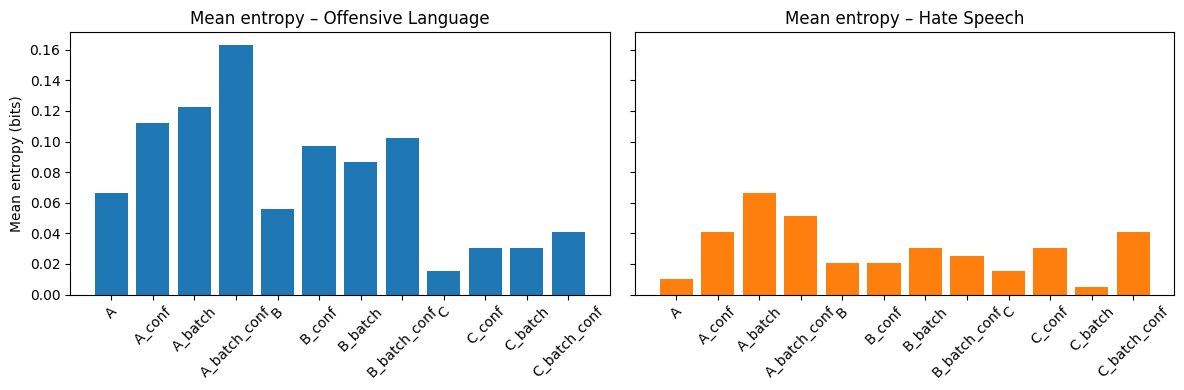

In [102]:
# Visualize Entropy
import pandas as pd
import matplotlib.pyplot as plt

# palette and ordering
palette = {'OL': '#1f77b4', 'HS': '#ff7f0e'}
condition_order = [
    'A', 'A_conf', 'A_batch', 'A_batch_conf',
    'B', 'B_conf', 'B_batch', 'B_batch_conf',
    'C', 'C_conf', 'C_batch', 'C_batch_conf'
]

# make sure the rows follow that order
mean_entropies = (
    mean_entropy_wide
      .set_index('cond_clean')
      .reindex(condition_order)
)

# ---------------- side-by-side plots -----------------
fig, axes = plt.subplots(
    nrows=1, ncols=2, figsize=(12, 4), sharey=True     # 1×2 layout
)

# Offensive-language entropy
axes[0].bar(
    mean_entropies.index,
    mean_entropies['mean_entropy_OL'],
    color=palette['OL']
)
axes[0].set_title('Mean entropy – Offensive Language')
axes[0].set_ylabel('Mean entropy (bits)')
axes[0].tick_params(axis='x', rotation=45)

# Hate-speech entropy
axes[1].bar(
    mean_entropies.index,
    mean_entropies['mean_entropy_HS'],
    color=palette['HS']
)
axes[1].set_title('Mean entropy – Hate Speech')
axes[1].tick_params(axis='x', rotation=45)

fig.tight_layout()
plt.show()

<a id="certainty_2"></a>
## Approach 2 to certainty assessment (conf conditions) - LLM self-reported Confidence

i.e., Group by Tweet and Condition and Calculate the mean self-reported confidence scores
e.g.   
tweet A in condition X: OL-Confidence-Scores: 4, 3, 4 --> Confidenc: = 3.66
tweet 4 in condition X: OL-Confidence-Scores: 4, 4, 4 --> Confidenc: = 4.00combined_df

In [105]:
combined_df.head()

,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,R1_label,R2_label,R3_label,R1_score,...,R3_score,R1_Token1,R1_Token2,R1_Token3,R2_Token1,R2_Token2,R2_Token3,R3_Token1,R3_Token2,R3_Token3
3200,1,1,811,Fat fucking funky nasty ass hoes,A_conf,few-shot,OL,OLHS,OL,4.0,...,4.0,OL -0.000204 \nHS -8.500204 \nOLS -15.375204\nHL -16.000204\n OL -16.375204\ndtype: float64,", -0.575942 \nHS -0.825942 \nH -13.325942\n HS -15.450942\nHP -15.575942\ndtype: float64",-0.575942 \n4 -0.825942 \n3 -13.325942\n -15.450942\n -15.575942\ndtype: float64,OL -0.000097 \nHS -9.250096 \nOLS -15.625096\nHL -16.375097\n OL -16.500097\ndtype: float64,"HS -0.386876 \n, -1.136876 \nH -13.011875\nHC -14.886875\n HS -15.011875\ndtype: float64",", -0.386876 \n , -1.136876 \n', -13.011875\n， -14.886875\n,, -15.011875\ndtype: float64",OL -0.000097 \nHS -9.250096 \nOLS -15.625096\nHL -16.375097\n OL -16.500097\ndtype: float64,"HS -0.474081 \n, -0.974081 \nH -13.099081\nHP -14.974081\nHC -14.974081\ndtype: float64",-0.474081 \n4 -0.974081 \n3 -13.099081\n -14.974081\n -14.974081\ndtype: float64
3201,1,1,811,Fat fucking funky nasty ass hoes,B_conf,few-shot,OL,HSOL,HSOL,4.0,...,3.0,HS -0.100214 \nOL -2.350214 \nHL -12.475214\nOLS -12.725214\n HS -14.600214\ndtype: float64,", 0.000 \n , -24.500\n', -24.750\n， -25.750\n، -26.375\ndtype: float64",0.000 \n4 -24.500\n3 -24.750\n2 -25.750\n -26.375\ndtype: float64,OL -0.693159 \nHS -0.693159 \nHL -12.068159\nOLS -12.193159\n HS -15.068159\ndtype: float64,"OL -0.000204 \n, -8.500203 \nO -18.125204\n OL -19.125204\nAL -19.625204\ndtype: float64",", -0.000204 \n', -8.500203 \n , -18.125204\n， -19.125204\n,, -19.625204\ndtype: float64",HS -0.100214 \nOL -2.350214 \nHL -12.475214\nOLS -12.725214\n HS -14.600214\ndtype: float64,"OL -0.000204 \n, -8.500203 \nO -18.625204\n OL -18.875204\nAL -19.125204\ndtype: float64",", -0.000204 \n , -8.500203 \n', -18.625204\n， -18.875204\n,, -19.125204\ndtype: float64"
3202,1,1,811,Fat fucking funky nasty ass hoes,C.OL_conf,few-shot,OL,OL,OL,4.0,...,4.0,OL 0.000 \n OL -18.375\nOLA -23.125\nAL -23.250\nOW -23.375\ndtype: float64,", 0.000 \n', -22.500\n , -22.750\n， -24.125\n,, -24.500\ndtype: float64",0.000 \n4 -22.500\n3 -22.750\n -24.125\n -24.500\ndtype: float64,OL 0.000 \n OL -18.375\nOLA -23.125\nAL -23.250\nOW -23.375\ndtype: float64,", 0.000 \n', -22.500\n , -22.750\n， -24.125\n,, -24.500\ndtype: float64",0.000 \n4 -22.500\n3 -22.750\n -24.125\n -24.500\ndtype: float64,OL 0.000 \n OL -18.375\nOLA -23.000\nOl -23.125\nAL -23.375\ndtype: float64,", 0.000 \n , -22.625\n', -23.250\n， -24.125\n,, -24.625\ndtype: float64",0.000 \n4 -22.625\n3 -23.250\n -24.125\n -24.625\ndtype: float64
3203,1,1,811,Fat fucking funky nasty ass hoes,C.HS_conf,few-shot,HS,HS,none,4.0,...,2.0,HS -0.023253 \nnone -3.773253 \n HS -12.523253\nGS -14.023253\nHF -14.023253\ndtype: float64,", 0.000 \n', -21.625\n , -22.750\n， -24.750\n,, -25.000\ndtype: float64",0.000 \n4 -21.625\n3 -22.750\n2 -24.750\n -25.000\ndtype: float64,HS -0.11284 \nnone -2.23784 \n HS -11.86284\nNone -12.86284\nGS -13.36284\ndtype: float64,", 0.000 \n', -22.000\n , -22.625\n， -23.875\n,, -24.250\ndtype: float64",0.000 \n4 -22.000\n3 -22.625\n2 -23.875\n -24.250\ndtype: float64,HS -0.11284 \nnone -2.23784 \n HS -11.86284\nNone -12.86284\nGS -13.36284\ndtype: float64,", 0.000 \n , -19.375\n', -21.875\n، -21.875\n， -22.000\ndtype: float64",0.000 \n1 -19.375\n2 -21.875\n4 -21.875\n3 -22.000\ndtype: float64
3204,1,1,811,Fat fucking funky nasty ass hoes,A,few-shot,OLHS,OL,OLHS,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [113]:
# Create DF for confidencs score investigation 
# --> i.e., merge the C.OL and C.HS conditions to one condition
# base df
confidence_df = combined_df[combined_df['condition'].str.contains(r"conf", case=False, na=False)][
    ['batch_id', 'tweet_in_batch', 'tweet_id',  'tweet', 
     'condition', 
     'shot', 
     'R1_label', 'R2_label', 'R3_label',
     'R1_score', 'R2_score', 'R3_score']].copy()

# extract binary OL and HS labels for every row 
confidence_df['R1_OL'] = np.where(['OL' in label for label in confidence_df['R1_label']], 1, 0)
confidence_df['R2_OL'] = np.where(['OL' in label for label in confidence_df['R2_label']], 1, 0)
confidence_df['R3_OL'] = np.where(['OL' in label for label in confidence_df['R3_label']], 1, 0)
confidence_df['R1_HS'] = np.where(['HS' in label for label in confidence_df['R1_label']], 1, 0)
confidence_df['R2_HS'] = np.where(['HS' in label for label in confidence_df['R2_label']], 1, 0)
confidence_df['R3_HS'] = np.where(['HS' in label for label in confidence_df['R3_label']], 1, 0)
confidence_df['R1_OL_confidence'] = confidence_df['R1_score'] 
confidence_df['R2_OL_confidence'] = confidence_df['R1_score'] 
confidence_df['R3_OL_confidence'] = confidence_df['R1_score'] 
confidence_df['R1_HS_confidence'] = confidence_df['R1_score'] 
confidence_df['R2_HS_confidence'] = confidence_df['R1_score'] 
confidence_df['R3_HS_confidence'] = confidence_df['R1_score'] 

# create additional C. col for C.HS and C.OL cases
confidence_df['cond_clean'] = confidence_df['condition'].str.replace(r'\.OL|\.HS', '', regex=True)


# A & B conditions --> nothing special to do --> join binary ratings
confidence_df_A_B = confidence_df[confidence_df['condition']
                            .str.contains(r'[AB]', na=False)].copy()[key_cols]
confidence_df_A_B = confidence_df_A_B.merge(confidence_df[['tweet', 'cond_clean', 
                                                  'R1_OL', 'R2_OL', 'R3_OL',
                                                  'R1_HS', 'R2_HS', 'R3_HS', 
                                                  'R1_OL_confidence', 
                                                  'R2_OL_confidence', 
                                                  'R3_OL_confidence', 
                                                  'R1_HS_confidence', 
                                                  'R2_HS_confidence', 
                                                  'R3_HS_confidence']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])

# C conditions --> sepcial: join binary OL ratings from C.OL base df 
#                           same for binary HS ratings
confidence_df_C = confidence_df[key_cols].copy().drop_duplicates(subset=['tweet_id', 'cond_clean'])

# join binary OL ratings
confidence_df_C = confidence_df_C.merge(confidence_df[confidence_df['condition'].str.contains(r'C\.OL', na=False)]
                                  [['tweet', 'cond_clean', 'R1_OL', 'R2_OL', 'R3_OL',
                                   'R1_OL_confidence', 'R2_OL_confidence', 'R3_OL_confidence']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])
# join binary HS ratings
confidence_df_C = confidence_df_C.merge(confidence_df[confidence_df['condition'].str.contains(r'C\.HS', na=False)]
                                  [['tweet', 'cond_clean', 'R1_HS', 'R2_HS', 'R3_HS',
                                   'R1_HS_confidence', 'R2_HS_confidence', 'R3_HS_confidence']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])


# Concat to get the final reformatted df for calculating entropies
confidence_df = pd.concat([confidence_df_A_B, confidence_df_C], 
                       ignore_index=True, sort=False)


# Checks: --> the number of C rows should have halved --> WORKS 
print(confidence_df_A_B.shape)
print(confidence_df_C.shape)
print(confidence_df.shape)
# confidence_df.head()

(720, 18)
(360, 18)
(1080, 18)


,batch_id,tweet_in_batch,tweet_id,tweet,shot,cond_clean,R1_OL,R2_OL,R3_OL,R1_HS,R2_HS,R3_HS,R1_OL_confidence,R2_OL_confidence,R3_OL_confidence,R1_HS_confidence,R2_HS_confidence,R3_HS_confidence
0,1,1,811,Fat fucking funky nasty ass hoes,few-shot,A_conf,1,1,1,0,1,0,4.0,4.0,4.0,4.0,4.0,4.0
1,1,1,811,Fat fucking funky nasty ass hoes,few-shot,B_conf,1,1,1,0,1,1,4.0,4.0,4.0,4.0,4.0,4.0
2,1,1,811,Fat fucking funky nasty ass hoes,few-shot,A_batch_conf,1,1,1,1,1,1,4.0,4.0,4.0,4.0,4.0,4.0
3,1,1,811,Fat fucking funky nasty ass hoes,few-shot,B_batch_conf,1,1,1,0,0,0,3.0,3.0,3.0,3.0,3.0,3.0
4,1,2,742,Up early then a bitch driving to denton omg can I move already,few-shot,A_conf,1,1,1,0,0,0,4.0,4.0,4.0,4.0,4.0,4.0


In [123]:
# Get Mean Confidence Scores per Tweet and Condition
confidence_df['mean_tweet_conf_OL'] = (confidence_df[
    ['R1_OL_confidence', 'R2_OL_confidence', 'R3_OL_confidence']]
                                       .mean(axis=1, numeric_only=True))

confidence_df['mean_tweet_conf_HS'] = (confidence_df[
    ['R1_HS_confidence', 'R2_HS_confidence', 'R3_HS_confidence']]
                                       .mean(axis=1, numeric_only=True))

# Calculcate Mean Entropies per condition and Outcome (HS/OL)
mean_confidence_wide = (
    confidence_df.groupby('cond_clean', as_index=False)
      .agg(mean_confidence_OL = ('mean_tweet_conf_OL', 'mean'),
           mean_confidence_HS = ('mean_tweet_conf_HS', 'mean'))
)
mean_confidence_wide

,cond_clean,mean_confidence_OL,mean_confidence_HS
0,A_batch_conf,3.527778,3.527778
1,A_conf,3.555556,3.555556
2,B_batch_conf,3.372222,3.372222
3,B_conf,3.516667,3.516667
4,C_batch_conf,3.344444,3.783333
5,C_conf,3.583333,3.344444


In [ ]:
### PLOT

<a id="certainty_3"></a>
## Approach 3 to certainty assessment (only non-batch conditions) - LogProb Comparison

i.e., extract the logprobs for the next tokens 
e.g.   
tweet A in condition X: OL-Confidence-Scores: 4, 3, 4 --> Confidenc: = 3.66
tweet 4 in condition X: OL-Confidence-Scores: 4, 4, 4 --> Confidenc: = 4.00combined_df